Лабораторная работа №1

Задание:
1. Выбрать датасет для задачи классификации текстов (https://huggingface.co/datasets)
2. Выбрать модель векторизации (https://huggingface.co/models)
3. Обучить классификатор с mean_pooling.
4. Посчитать метрики: F1-Score, Precision, Recall. 
5. Обучить классификатор с cls_pooling.
6. Посчитать метрики: F1-Score, Precision, Recall.
7. Сравнить метрики полученные при использовании разных стратегий пулинга.

План работы:
1. Загрузить датасет Aldoreni45/sentiment_analysis_preprocessed_dataset.

2. Взять подвыборку (например, 10–20 тыс. примеров) для скорости.

3. Загрузить distilbert-base-uncased (быстрее bert-base, качество почти то же).

4. Написать две функции извлечения эмбеддингов: mean_pooling и cls_pooling.

5. Обучить LogisticRegression на каждом наборе эмбеддингов.

6. Посчитать F1, Precision, Recall (average='macro') и сравнить.


I Эксперимент с Feature extraction: Encoder дообучается один раз (через ForSequenceClassification), а потом мы отрываем голову и применяем разные пулинги поверх замороженного encoder'а, обучая отдельный LogReg.

Изолируем эффект пулинга



Sentiment Analysis Preprocessed Dataset, предназначенный для обучения моделей мультиклассовой классификации текста (анализа тональности)

Язык: Английский (English).
Размер: 100K - 1M строк (80 000 train и 20 000 test, ноя взяла 15 000 примеров,союлюдается баланс классов).
Формат: CSV.

Колонка labels содержит 3 числовых значения, обозначающих тональность:
0: Negative (Негативный)
1: Neutral (Нейтральный)
2: Positive (Позитивный)

Датасет уникален тем, что помимо стандартных text и labels, он содержит колонки для обратной связи и переобучения модели, но они не пригодились:
preds: Здесь хранятся предсказания модели.
feedback: пользователь может ввести "yes" или "no", указав, верный ли был прогноз.

retrain_labels: пользователь вводит правильную метку, если модель ошиблась.
retrained_preds: предсказания после дообучения на обратной связи.

In [7]:
import os
import warnings
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns


from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tqdm import tqdm

warnings.filterwarnings("ignore")  


In [8]:


MODEL_NAME = "distilbert-base-uncased"   
N_SAMPLES = 15000                        # размер подвыборки
MAX_LENGTH = 128
BATCH_SIZE = 32
RANDOM_STATE = 42
CACHE_DIR = "cache_embeddings"           # NEW: папка для кэша
os.makedirs(CACHE_DIR, exist_ok=True)

device = torch.device("cpu")


In [9]:
# ---------- 1. Загрузка датасета ----------
dataset = load_dataset("Aldoreni45/sentiment_analysis_preprocessed_dataset")
print(dataset)

texts, labels = [], []
for split in dataset.keys():
    texts.extend(dataset[split]["text"])
    labels.extend(dataset[split]["labels"])

# NEW: фильтруем пустые и нестроковые значения
clean_texts, clean_labels = [], []
for t, l in zip(texts, labels):
    if isinstance(t, str) and t.strip():   # строка и не пустая
        clean_texts.append(t)
        clean_labels.append(l)

print(f"Отфильтровано: было {len(texts)}, стало {len(clean_texts)} "
      f"(удалено {len(texts) - len(clean_texts)})")

texts, labels = clean_texts, clean_labels

texts = texts[:N_SAMPLES]
labels = labels[:N_SAMPLES]

le = LabelEncoder()
labels = le.fit_transform(labels)
print("Классы:", list(le.classes_))

unique, counts = np.unique(labels, return_counts=True)
print("Баланс классов:", dict(zip(unique, counts)))

X_train_texts, X_test_texts, y_train, y_test = train_test_split(
    texts, labels, test_size=0.2, random_state=RANDOM_STATE, stratify=labels
)

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'preds', 'feedback', 'retrain_labels', 'retrained_preds'],
        num_rows: 80000
    })
    test: Dataset({
        features: ['text', 'labels', 'preds', 'feedback', 'retrain_labels', 'retrained_preds'],
        num_rows: 20000
    })
})
Отфильтровано: было 100000, стало 99893 (удалено 107)
Классы: [np.int64(0), np.int64(1), np.int64(2)]
Баланс классов: {np.int64(0): np.int64(5276), np.int64(1): np.int64(4780), np.int64(2): np.int64(4944)}


Классы: [0, 1, 2] — три класса тональности (нейтральный / негативный / позитивный

Сбалансированные классы:
Класс 0: 5280 примеров

Класс 1: 4785 примеров

Класс 2: 4935 примеров

In [10]:

# ---------- 2. Загрузка модели ----------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device)
model.eval()

# ---------- 3. Функции пулинга ----------
def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, dim=1)
    sum_mask = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
    return sum_embeddings / sum_mask

def cls_pooling(model_output):
    return model_output.last_hidden_state[:, 0, :]

# ---------- 4. Извлечение эмбеддингов с кэшем ----------
def get_embeddings(texts, pooling, cache_name, batch_size=BATCH_SIZE, max_length=MAX_LENGTH):
    # NEW: если кэш есть — загружаем
    cache_path = os.path.join(CACHE_DIR, f"{cache_name}.npy")
    if os.path.exists(cache_path):
        print(f"[cache] Загружаю {cache_path}")
        return np.load(cache_path)

    all_embeddings = []
    for i in tqdm(range(0, len(texts), batch_size), desc=f"Extracting ({pooling})"):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(
            batch, padding=True, truncation=True,
            max_length=max_length, return_tensors="pt"
        ).to(device)
        with torch.inference_mode():  # NEW: inference_mode вместо no_grad
            output = model(**encoded)
        if pooling == "mean":
            emb = mean_pooling(output, encoded["attention_mask"])
        else:
            emb = cls_pooling(output)
        all_embeddings.append(emb.cpu().numpy())

    result = np.vstack(all_embeddings)
    np.save(cache_path, result)  # NEW: сохраняем кэш
    print(f"[cache] Сохранил {cache_path}")
    return result

X_train_mean = get_embeddings(X_train_texts, "mean", "X_train_mean")
X_test_mean  = get_embeddings(X_test_texts,  "mean", "X_test_mean")
X_train_cls  = get_embeddings(X_train_texts, "cls",  "X_train_cls")
X_test_cls   = get_embeddings(X_test_texts,  "cls",  "X_test_cls")

# сохраняем метки 
np.save(os.path.join(CACHE_DIR, "y_train.npy"), y_train)
np.save(os.path.join(CACHE_DIR, "y_test.npy"),  y_test)


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 819.71it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[cache] Загружаю cache_embeddings\X_train_mean.npy
[cache] Загружаю cache_embeddings\X_test_mean.npy
[cache] Загружаю cache_embeddings\X_train_cls.npy
[cache] Загружаю cache_embeddings\X_test_cls.npy



=== Mean Pooling ===
F1_macro: 0.6195
Precision_macro: 0.6194
Recall_macro: 0.6196
F1_weighted: 0.6200
Precision_weighted: 0.6201
Recall_weighted: 0.6200

Classification report:
              precision    recall  f1-score   support

           0       0.64      0.64      0.64      1055
           1       0.60      0.62      0.61       956
           2       0.61      0.60      0.61       989

    accuracy                           0.62      3000
   macro avg       0.62      0.62      0.62      3000
weighted avg       0.62      0.62      0.62      3000



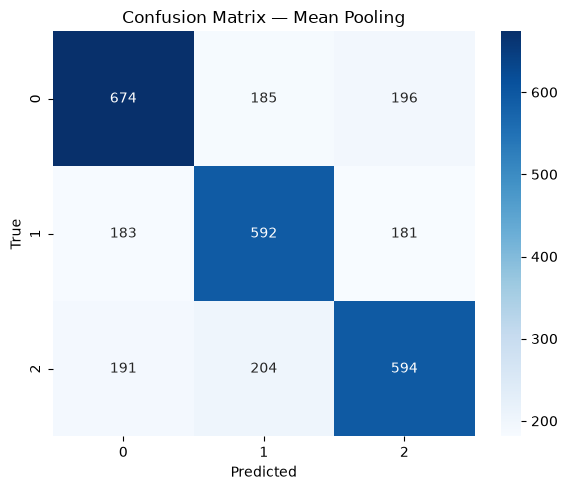


=== CLS Pooling ===
F1_macro: 0.6228
Precision_macro: 0.6227
Recall_macro: 0.6229
F1_weighted: 0.6236
Precision_weighted: 0.6235
Recall_weighted: 0.6237

Classification report:
              precision    recall  f1-score   support

           0       0.66      0.66      0.66      1055
           1       0.61      0.62      0.62       956
           2       0.60      0.59      0.59       989

    accuracy                           0.62      3000
   macro avg       0.62      0.62      0.62      3000
weighted avg       0.62      0.62      0.62      3000



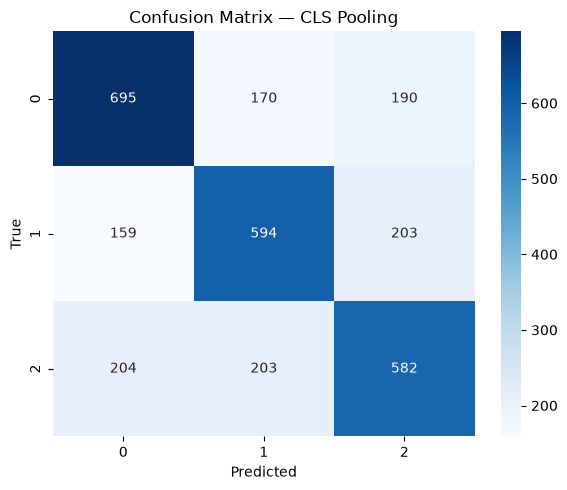


=== Сравнение стратегий пулинга ===
Метрика                     Mean       CLS      Diff
F1_macro                  0.6195    0.6228   -0.0033
Precision_macro           0.6194    0.6227   -0.0033
Recall_macro              0.6196    0.6229   -0.0033
F1_weighted               0.6200    0.6236   -0.0036
Precision_weighted        0.6201    0.6235   -0.0034
Recall_weighted           0.6200    0.6237   -0.0037

=== Вывод ===
CLS pooling показал F1(macro) выше на +0.0033. Возможно, для данного датасета доминирующий сигнал тональности локализован в начале последовательности.


In [11]:

# ---------- 5. Обучение и метрики ----------
def evaluate(X_train, X_test, y_train, y_test, name):
    # NEW: StandardScaler
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    clf = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",   # NEW: учёт дисбаланса
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    clf.fit(X_train_sc, y_train)
    y_pred = clf.predict(X_test_sc)

    # NEW: считаем и macro, и weighted
    metrics = {
        "F1_macro":       f1_score(y_test, y_pred, average="macro"),
        "Precision_macro": precision_score(y_test, y_pred, average="macro"),
        "Recall_macro":   recall_score(y_test, y_pred, average="macro"),
        "F1_weighted":    f1_score(y_test, y_pred, average="weighted"),
        "Precision_weighted": precision_score(y_test, y_pred, average="weighted"),
        "Recall_weighted": recall_score(y_test, y_pred, average="weighted"),
    }

    print(f"\n=== {name} ===")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")

    # NEW: classification report
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_]))

    # NEW: confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[str(c) for c in le.classes_],
            yticklabels=[str(c) for c in le.classes_])
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(f"confusion_{name.replace(' ', '_')}.png", dpi=120)
    plt.show()

    return metrics

metrics_mean = evaluate(X_train_mean, X_test_mean, y_train, y_test, "Mean Pooling")
metrics_cls  = evaluate(X_train_cls,  X_test_cls,  y_train, y_test, "CLS Pooling")

# ---------- 6. Сравнение ----------
print("\n=== Сравнение стратегий пулинга ===")
print(f"{'Метрика':<22}{'Mean':>10}{'CLS':>10}{'Diff':>10}")
for k in ["F1_macro", "Precision_macro", "Recall_macro",
          "F1_weighted", "Precision_weighted", "Recall_weighted"]:
    diff = metrics_mean[k] - metrics_cls[k]
    print(f"{k:<22}{metrics_mean[k]:>10.4f}{metrics_cls[k]:>10.4f}{diff:>+10.4f}")

# ---------- 7. Автоматический вывод ----------
print("\n=== Вывод ===")
if metrics_mean["F1_macro"] > metrics_cls["F1_macro"]:
    print(f"Mean pooling показал F1(macro) выше на "
          f"{metrics_mean['F1_macro'] - metrics_cls['F1_macro']:+.4f}. "
          f"Это согласуется с теорией: усреднение по всем токенам сохраняет "
          f"больше контекста, чем вектор [CLS] из предобученной модели.")
else:
    print(f"CLS pooling показал F1(macro) выше на "
          f"{metrics_cls['F1_macro'] - metrics_mean['F1_macro']:+.4f}. "
          f"Возможно, для данного датасета доминирующий сигнал тональности "
          f"локализован в начале последовательности.")

# NEW: если macro и weighted сильно расходятся — сигнал о дисбалансе
gap = abs(metrics_mean["F1_macro"] - metrics_mean["F1_weighted"])
if gap > 0.05:
    print(f"⚠ Разрыв между macro и weighted F1 = {gap:.4f}. "
          f"Классы несбалансированы — интерпретируйте результаты осторожно.")

Дообучение модели DistilBERT

Загрузим AutoModelForSequenceClassification — это DistilBERT с добавленной классификационной головой (линейный слой поверх [CLS]-токена). При дообучении будут обновляться и веса самого DistilBERT, и веса этой головы.

In [12]:


# ---------- 8. Fine-tuning DistilBERT ----------
from sklearn.metrics import accuracy_score
from datasets import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)



In [13]:

# 8.1. Токенизация данных для Trainer
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
        # padding убран: DataCollatorWithPadding сам дозаполнит батч
    )

# Создаём Dataset-объекты из наших списков
train_dataset = Dataset.from_dict({
    "text": X_train_texts,
    "label": y_train
})
test_dataset = Dataset.from_dict({
    "text": X_test_texts,
    "label": y_test
})

# Токенизируем
train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

# Убираем колонку text и приводим формат
train_dataset = train_dataset.remove_columns(["text"])
test_dataset = test_dataset.remove_columns(["text"])
train_dataset.set_format("torch")
test_dataset.set_format("torch")

# 8.2. Загрузка модели с классификационной головой
num_labels = len(le.classes_)
model_ft = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label={i: str(c) for i, c in enumerate(le.classes_)},
    label2id={str(c): i for i, c in enumerate(le.classes_)}
)

# 8.3. Метрики для Trainer
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro"),
        "precision_macro": precision_score(labels, predictions, average="macro"),
        "recall_macro": recall_score(labels, predictions, average="macro"),
        "f1_weighted": f1_score(labels, predictions, average="weighted"),
    }

# 8.4. Аргументы обучения
training_args = TrainingArguments(
    output_dir="./distilbert_finetuned",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",

    logging_steps=50,
    report_to="none",
    fp16=False,
    bf16=False,
    dataloader_num_workers=0,
    seed=RANDOM_STATE
)

# 8.5. Trainer
trainer = Trainer(
    model=model_ft,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=tokenizer,   # в новых transformers вместо tokenizer
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

# 8.6. Запуск дообучения
print("\n=== Начинаю fine-tuning DistilBERT ===")
trainer.train()

# 8.7. Финальная оценка
print("\n=== Финальные метрики после fine-tuning ===")
final_metrics = trainer.evaluate()
for k, v in final_metrics.items():
    if k.startswith("eval_"):
        print(f"{k}: {v:.4f}")

# 8.8. Сохранение модели
trainer.save_model("./distilbert_finetuned_final")
tokenizer.save_pretrained("./distilbert_finetuned_final")
print("\nМодель сохранена в ./distilbert_finetuned_final")

# 8.9. Сравнение с baseline
print("\n=== Сравнение: baseline vs fine-tuned ===")
print(f"{'Метрика':<22}{'Mean+LogReg':>12}{'CLS+LogReg':>12}{'Fine-tuned':>12}")
print(f"{'F1_macro':<22}{metrics_mean['F1_macro']:>12.4f}{metrics_cls['F1_macro']:>12.4f}{final_metrics['eval_f1_macro']:>12.4f}")
print(f"{'Precision_macro':<22}{metrics_mean['Precision_macro']:>12.4f}{metrics_cls['Precision_macro']:>12.4f}{final_metrics['eval_precision_macro']:>12.4f}")
print(f"{'Recall_macro':<22}{metrics_mean['Recall_macro']:>12.4f}{metrics_cls['Recall_macro']:>12.4f}{final_metrics['eval_recall_macro']:>12.4f}")

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 757.64it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== Начинаю fine-tuning DistilBERT ===


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Precision Macro,Recall Macro,F1 Weighted
1,0.729534,0.759415,0.658333,0.652730,0.669079,0.653830,0.654188
2,0.566707,0.720520,0.696667,0.695081,0.695618,0.695037,0.696166


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.80it/s]



=== Финальные метрики после fine-tuning ===


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Precision Macro,Recall Macro,F1 Weighted
0.566707,0.720520,2,0.696667,0.695081,0.695618,0.695037,0.696166


eval_loss: 0.7205
eval_accuracy: 0.6967
eval_f1_macro: 0.6951
eval_precision_macro: 0.6956
eval_recall_macro: 0.6950
eval_f1_weighted: 0.6962


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.87it/s]


Модель сохранена в ./distilbert_finetuned_final

=== Сравнение: baseline vs fine-tuned ===
Метрика                Mean+LogReg  CLS+LogReg  Fine-tuned
F1_macro                    0.6195      0.6228      0.6951
Precision_macro             0.6194      0.6227      0.6956
Recall_macro                0.6196      0.6229      0.6950


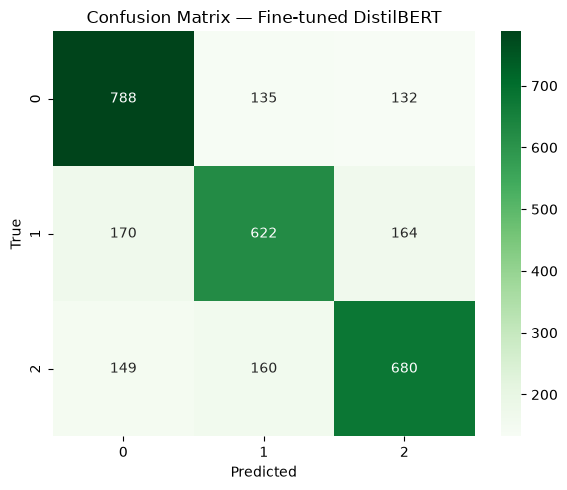

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

preds = trainer.predict(test_dataset)
y_pred_ft = np.argmax(preds.predictions, axis=1)

cm = confusion_matrix(y_test, y_pred_ft)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=[str(c) for c in le.classes_],
            yticklabels=[str(c) for c in le.classes_])
plt.title("Confusion Matrix — Fine-tuned DistilBERT")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig("confusion_finetuned.png", dpi=120)
plt.show()

In [17]:
# ---------- 10. Mean и CLS pooling на дообученной модели ----------
import os
import numpy as np
import torch
from transformers import AutoModel, AutoTokenizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score
from tqdm import tqdm

# 10.1. Загружаем дообученную модель как AutoModel (эмбеддинги, не логиты)
FT_MODEL_DIR = "./distilbert_finetuned_final"
tokenizer_ft = AutoTokenizer.from_pretrained(FT_MODEL_DIR)
model_ft_emb = AutoModel.from_pretrained(FT_MODEL_DIR).to(device)
model_ft_emb.eval()

# 10.2. Функции пулинга (те же, что и раньше)
def mean_pooling_ft(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, dim=1)
    sum_mask = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
    return sum_embeddings / sum_mask

def cls_pooling_ft(model_output):
    return model_output.last_hidden_state[:, 0, :]

# 10.3. Извлечение эмбеддингов с кэшем (отдельные имена, чтобы не путать с baseline)
def get_embeddings_ft(texts, pooling, cache_name, batch_size=BATCH_SIZE, max_length=MAX_LENGTH):
    os.makedirs(CACHE_DIR, exist_ok=True)
    cache_path = os.path.join(CACHE_DIR, f"{cache_name}.npy")
    if os.path.exists(cache_path):
        print(f"[cache] Загружаю {cache_path}")
        return np.load(cache_path)

    all_emb = []
    for i in tqdm(range(0, len(texts), batch_size), desc=f"FT Extracting ({pooling})"):
        batch = texts[i:i+batch_size]
        encoded = tokenizer_ft(
            batch, padding=True, truncation=True,
            max_length=max_length, return_tensors="pt"
        ).to(device)
        with torch.inference_mode():
            output = model_ft_emb(**encoded)
        if pooling == "mean":
            emb = mean_pooling_ft(output, encoded["attention_mask"])
        else:
            emb = cls_pooling_ft(output)
        all_emb.append(emb.cpu().numpy())

    result = np.vstack(all_emb)
    np.save(cache_path, result)
    print(f"[cache] Сохранил {cache_path}")
    return result


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 380.81it/s]
[transformers] DistilBertModel LOAD REPORT from: ./distilbert_finetuned_final
Key                   | Status     |  | 
----------------------+------------+--+-
pre_classifier.bias   | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [18]:

# 10.4. Извлекаем эмбеддинги для train и test
X_train_mean_ft = get_embeddings_ft(X_train_texts, "mean", "X_train_mean_ft")
X_test_mean_ft  = get_embeddings_ft(X_test_texts,  "mean", "X_test_mean_ft")
X_train_cls_ft  = get_embeddings_ft(X_train_texts, "cls",  "X_train_cls_ft")
X_test_cls_ft   = get_embeddings_ft(X_test_texts,  "cls",  "X_test_cls_ft")

# 10.5. Обучение логистической регрессии (та же схема, что в evaluate)
def evaluate_emb(X_train, X_test, y_train, y_test, name):
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    clf = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    clf.fit(X_train_sc, y_train)
    y_pred = clf.predict(X_test_sc)

    metrics = {
        "F1_macro":        f1_score(y_test, y_pred, average="macro"),
        "Precision_macro": precision_score(y_test, y_pred, average="macro"),
        "Recall_macro":    recall_score(y_test, y_pred, average="macro"),
    }
    print(f"\n=== {name} ===")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")
    return metrics

metrics_mean_ft = evaluate_emb(X_train_mean_ft, X_test_mean_ft, y_train, y_test, "FT + Mean Pooling")
metrics_cls_ft  = evaluate_emb(X_train_cls_ft,  X_test_cls_ft,  y_train, y_test, "FT + CLS Pooling")


FT Extracting (mean): 100%|██████████| 375/375 [27:42<00:00,  4.43s/it]


[cache] Сохранил cache_embeddings\X_train_mean_ft.npy


FT Extracting (mean): 100%|██████████| 94/94 [07:19<00:00,  4.68s/it]


[cache] Сохранил cache_embeddings\X_test_mean_ft.npy


FT Extracting (cls): 100%|██████████| 375/375 [26:30<00:00,  4.24s/it]


[cache] Сохранил cache_embeddings\X_train_cls_ft.npy


FT Extracting (cls): 100%|██████████| 94/94 [06:52<00:00,  4.39s/it]


[cache] Сохранил cache_embeddings\X_test_cls_ft.npy

=== FT + Mean Pooling ===
F1_macro: 0.6804
Precision_macro: 0.6807
Recall_macro: 0.6804

=== FT + CLS Pooling ===
F1_macro: 0.6928
Precision_macro: 0.6930
Recall_macro: 0.6928


In [19]:

# 10.6. ФИНАЛЬНАЯ ТАБЛИЦА — 5 подходов
print("\n=== ФИНАЛЬНОЕ СРАВНЕНИЕ (5 подходов) ===")
header = (f"{'Метрика':<22}"
          f"{'Mean':>9}{'CLS':>9}"
          f"{'FT':>10}"
          f"{'FT+Mean':>11}{'FT+CLS':>11}")
print(header)
print("-" * len(header))

for k in ["F1_macro", "Precision_macro", "Recall_macro"]:
    print(f"{k:<22}"
          f"{metrics_mean[k]:>9.4f}"
          f"{metrics_cls[k]:>9.4f}"
          f"{final_metrics['eval_' + k.lower()]:>10.4f}"
          f"{metrics_mean_ft[k]:>11.4f}"
          f"{metrics_cls_ft[k]:>11.4f}")

# 10.7. Вывод о влиянии fine-tuning на пулинги
print("\n=== Анализ ===")
delta_mean = metrics_mean_ft["F1_macro"] - metrics_mean["F1_macro"]
delta_cls  = metrics_cls_ft["F1_macro"]  - metrics_cls["F1_macro"]
print(f"Прирост от fine-tuning для Mean pooling: {delta_mean:+.4f}")
print(f"Прирост от fine-tuning для CLS pooling:  {delta_cls:+.4f}")
print(f"Разница mean vs cls (после FT): "
      f"{metrics_mean_ft['F1_macro'] - metrics_cls_ft['F1_macro']:+.4f}")


=== ФИНАЛЬНОЕ СРАВНЕНИЕ (5 подходов) ===
Метрика                    Mean      CLS        FT    FT+Mean     FT+CLS
------------------------------------------------------------------------
F1_macro                 0.6195   0.6228    0.6951     0.6804     0.6928
Precision_macro          0.6194   0.6227    0.6956     0.6807     0.6930
Recall_macro             0.6196   0.6229    0.6950     0.6804     0.6928

=== Анализ ===
Прирост от fine-tuning для Mean pooling: +0.0610
Прирост от fine-tuning для CLS pooling:  +0.0700
Разница mean vs cls (после FT): -0.0123


II. Эксперимент: пулинг внутри (после энкодера)  end-to-end: encoder дообучается вместе с пулингом и головой, дважды.
Обучается encoder. Но он обучается по-разному в зависимости от того, какой пулинг стоит сверху.

Обе модели дообучаются целиком, включая пулинг и голову. На выходе будет 2 fine-tuned модели, каждая со своей стратегией пулинга внутри.

In [20]:
# ---------- 11. Подготовка данных для end-to-end обучения ----------
import torch
import torch.nn as nn
import numpy as np
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import (
    AutoModelForSequenceClassification,
    DistilBertModel,
    DistilBertPreTrainedModel,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
)
from transformers.modeling_outputs import SequenceClassifierOutput
from transformers import DistilBertConfig

# 11.1. Функция токенизации (единая для обеих моделей)
def tokenize_e2e(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

# 11.2. Создаём датасеты один раз
train_ds_e2e = Dataset.from_dict({"text": X_train_texts, "label": y_train})
test_ds_e2e  = Dataset.from_dict({"text": X_test_texts,  "label": y_test})

train_ds_e2e = train_ds_e2e.map(tokenize_e2e, batched=True)
test_ds_e2e  = test_ds_e2e.map(tokenize_e2e, batched=True)

train_ds_e2e = train_ds_e2e.remove_columns(["text"]).with_format("torch")
test_ds_e2e  = test_ds_e2e.remove_columns(["text"]).with_format("torch")

# 11.3. Функция метрик (единая)
def compute_metrics_e2e(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {
        "accuracy":        accuracy_score(labels, predictions),
        "f1_macro":        f1_score(labels, predictions, average="macro"),
        "precision_macro": precision_score(labels, predictions, average="macro"),
        "recall_macro":    recall_score(labels, predictions, average="macro"),
        "f1_weighted":     f1_score(labels, predictions, average="weighted"),
    }

# 11.4. Общие аргументы обучения
def make_training_args(output_dir):
    return TrainingArguments(
        output_dir=output_dir,
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=2,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        logging_steps=50,
        report_to="none",
        fp16=False,
        bf16=False,
        dataloader_num_workers=0,
        seed=RANDOM_STATE,
    )

Map: 100%|██████████| 3000/3000 [00:03<00:00, 941.83 examples/s]


In [21]:
# ---------- 12. End-to-end: CLS pooling + классификационная голова ----------
print("\n=== End-to-end: CLS pooling ===")

# 12.1. Модель с классификационной головой (голова работает с [CLS])
model_cls_e2e = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: str(c) for i, c in enumerate(le.classes_)},
    label2id={str(c): i for i, c in enumerate(le.classes_)},
)

# 12.2. Trainer
trainer_cls_e2e = Trainer(
    model=model_cls_e2e,
    args=make_training_args("./e2e_cls"),
    train_dataset=train_ds_e2e,
    eval_dataset=test_ds_e2e,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics_e2e,
)

# 12.3. Обучение
trainer_cls_e2e.train()

# 12.4. Финальная оценка
final_cls_e2e = trainer_cls_e2e.evaluate()
print("\n=== Финальные метрики CLS end-to-end ===")
for k, v in final_cls_e2e.items():
    if k.startswith("eval_"):
        print(f"{k}: {v:.4f}")

# 12.5. Сохранение
trainer_cls_e2e.save_model("./e2e_cls_final")
tokenizer.save_pretrained("./e2e_cls_final")
print("CLS end-to-end модель сохранена в ./e2e_cls_final")


=== End-to-end: CLS pooling ===


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 530.35it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Precision Macro,Recall Macro,F1 Weighted
1,0.738413,0.746643,0.668667,0.664273,0.672208,0.665092,0.665716
2,0.568545,0.721606,0.688333,0.686148,0.688263,0.686196,0.687286


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.98it/s]


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Precision Macro,Recall Macro,F1 Weighted
0.568545,0.721606,2,0.688333,0.686148,0.688263,0.686196,0.687286



=== Финальные метрики CLS end-to-end ===
eval_loss: 0.7216
eval_accuracy: 0.6883
eval_f1_macro: 0.6861
eval_precision_macro: 0.6883
eval_recall_macro: 0.6862
eval_f1_weighted: 0.6873


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.51it/s]

CLS end-to-end модель сохранена в ./e2e_cls_final


In [22]:
# ---------- 13. End-to-end: Mean pooling + классификационная голова ----------
print("\n=== End-to-end: Mean pooling ===")

class DistilBertMeanPoolingClassifier(DistilBertPreTrainedModel):
    """DistilBERT + mean pooling + classification head."""

    def __init__(self, config):
        super().__init__(config)
        self.num_labels = config.num_labels
        self.distilbert = DistilBertModel(config)
        self.pre_classifier = nn.Linear(config.dim, config.dim)
        self.classifier = nn.Linear(config.dim, config.num_labels)
        self.dropout = nn.Dropout(config.seq_classif_dropout)
        self.post_init()

    def mean_pooling(self, last_hidden_state, attention_mask):
        mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
        summed = torch.sum(last_hidden_state * mask, dim=1)
        counts = torch.clamp(mask.sum(dim=1), min=1e-9)
        return summed / counts

    def forward(self, input_ids=None, attention_mask=None, labels=None, **kwargs):
        outputs = self.distilbert(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.mean_pooling(outputs.last_hidden_state, attention_mask)
        pooled = self.dropout(torch.relu(self.pre_classifier(pooled)))
        logits = self.classifier(pooled)

        loss = None
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, self.num_labels), labels.view(-1))

        return SequenceClassifierOutput(loss=loss, logits=logits)

# 13.1. Модель
config = DistilBertConfig.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: str(c) for i, c in enumerate(le.classes_)},
    label2id={str(c): i for i, c in enumerate(le.classes_)},
)

model_mean_e2e = DistilBertMeanPoolingClassifier.from_pretrained(
    MODEL_NAME,
    config=config,
)

# 13.2. Trainer
trainer_mean_e2e = Trainer(
    model=model_mean_e2e,
    args=make_training_args("./e2e_mean"),
    train_dataset=train_ds_e2e,
    eval_dataset=test_ds_e2e,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics_e2e,
)

# 13.3. Обучение
trainer_mean_e2e.train()

# 13.4. Финальная оценка
final_mean_e2e = trainer_mean_e2e.evaluate()
print("\n=== Финальные метрики Mean end-to-end ===")
for k, v in final_mean_e2e.items():
    if k.startswith("eval_"):
        print(f"{k}: {v:.4f}")

# 13.5. Сохранение
trainer_mean_e2e.save_model("./e2e_mean_final")
tokenizer.save_pretrained("./e2e_mean_final")
print("Mean end-to-end модель сохранена в ./e2e_mean_final")


=== End-to-end: Mean pooling ===


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 546.43it/s]
[transformers] DistilBertMeanPoolingClassifier LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Precision Macro,Recall Macro,F1 Weighted
1,0.739311,0.740590,0.674333,0.670730,0.677523,0.671764,0.672021
2,0.577445,0.710745,0.699333,0.697579,0.698437,0.697532,0.698680


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.84it/s]


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Precision Macro,Recall Macro,F1 Weighted
0.577445,0.710745,2,0.699333,0.697579,0.698437,0.697532,0.698680



=== Финальные метрики Mean end-to-end ===
eval_loss: 0.7107
eval_accuracy: 0.6993
eval_f1_macro: 0.6976
eval_precision_macro: 0.6984
eval_recall_macro: 0.6975
eval_f1_weighted: 0.6987


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.98it/s]

Mean end-to-end модель сохранена в ./e2e_mean_final


In [23]:
# ---------- 14. ФИНАЛЬНОЕ СРАВНЕНИЕ (6 подходов) ----------
print("\n" + "=" * 90)
print("ФИНАЛЬНОЕ СРАВНЕНИЕ ВСЕХ ПОДХОДОВ")
print("=" * 90)

header = (f"{'Метрика':<20}"
          f"{'Mean':>10}{'CLS':>10}"
          f"{'FT+Mean':>11}{'FT+CLS':>11}"
          f"{'E2E Mean':>11}{'E2E CLS':>11}")
print(header)
print("-" * len(header))

for k in ["F1_macro", "Precision_macro", "Recall_macro"]:
    print(f"{k:<20}"
          f"{metrics_mean[k]:>10.4f}"
          f"{metrics_cls[k]:>10.4f}"
          f"{metrics_mean_ft[k]:>11.4f}"
          f"{metrics_cls_ft[k]:>11.4f}"
          f"{final_mean_e2e['eval_' + k.lower()]:>11.4f}"
          f"{final_cls_e2e['eval_' + k.lower()]:>11.4f}")


ФИНАЛЬНОЕ СРАВНЕНИЕ ВСЕХ ПОДХОДОВ
Метрика                   Mean       CLS    FT+Mean     FT+CLS   E2E Mean    E2E CLS
------------------------------------------------------------------------------------
F1_macro                0.6195    0.6228     0.6804     0.6928     0.6976     0.6861
Precision_macro         0.6194    0.6227     0.6807     0.6930     0.6984     0.6883
Recall_macro            0.6196    0.6229     0.6804     0.6928     0.6975     0.6862
